# MZI Delay Arm -- Dense delta_L_um Sweep (Library Densification)

This notebook densifies `03_mzi_arm.ipynb`'s `delta_L_um` sweep at two `radius_um`
values. The resulting length-axis S-parameter library is read by
`pic_toolkit.optimization.arm_library` (arm-length interpolation for gradient-based
lattice-filter design) and, for the radius-2.5 µm points, by
`circuits/wdm_mux4_sax.ipynb`. Both stages use `03_mzi_arm.ipynb`'s geometry and sweep
tolerances unchanged:

- **Stage 1** (`radius_um=5.0`): extends `03_mzi_arm.ipynb`'s
  `{14.0, 15.0, 17.5, 20.0, 25.0, 30.0}` µm sweep to an even 2 µm grid from the
  geometry's floor (~13.27 µm) up to 34 µm.
- **Stage 2** (`radius_um=2.5`, the bend radius of the Mux4 tree's second-stage arms):
  the two arms `wdm_mux4_sax.ipynb` uses (`delta_L_um` = 7.5 µm and 7.640 µm, its ideal
  quarter-wave design value), plus a dense grid from 7 to 20 µm.

Each grid has its own directory under `si/data/sparams/mzi_arm/`. Points whose artifact
already exists with the same geometry, resolution and tolerances are reloaded rather
than re-simulated (`grid_sweep(..., reuse_existing=True)`).

**Do not use "Run All."** Each point is a 2-direction FDTD run at `resolution=40`
(~15 min on one core); a first run of both stages takes hours.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from pic_toolkit.meep_sim import mzi_arm
from pic_toolkit import sparams, sweep, style

style.apply_style()
%matplotlib inline


## 1. Stage 1 -- radius_um=5.0 dense grid

In [2]:
params = dict(mzi_arm.DEFAULT_PARAMS)  # same working copy convention as 03_mzi_arm.ipynb
params


{'wg_width_um': 0.5,
 'core_index': 2.7,
 'clad_index': 1.44,
 'polarization': 'TE',
 'wl_min_um': 1.3,
 'wl_max_um': 1.4,
 'resolution': 40,
 'dpml_um': 1.0,
 'radius_um': 5.0,
 'bend_type': 'euler',
 'extra_straight_um': 0.864,
 'lead_len_um': 3.0,
 'n_freq': 21,
 'margin_um': 1.5,
 'port_offset_um': 1.0,
 'source_offset_um': 0.5,
 'lead_overrun_um': 1.0}

### 1.1 Target grid

`extra_straight_um_for_delta_L` converts each target `delta_L_um` to this
geometry's own swept parameter (`extra_straight_um`), raising `ValueError` if
a target is below the floor (~13.27um at `radius_um=5.0`, `bend_type="euler"`)
-- none of these targets are.

In [3]:
EXISTING_DELTA_L_UM = [14.0, 15.0, 17.5, 20.0, 25.0, 30.0]  # already in si/data/sparams/mzi_arm/sweep/
NEW_DELTA_L_UM = [16.0, 18.0, 22.0, 24.0, 26.0, 28.0, 32.0, 34.0]  # this notebook's own new points

NEW_EXTRA_STRAIGHT_UM = [mzi_arm.extra_straight_um_for_delta_L(dl, params) for dl in NEW_DELTA_L_UM]
print(list(zip(NEW_DELTA_L_UM, [round(e, 4) for e in NEW_EXTRA_STRAIGHT_UM])))


[(16.0, 1.364), (18.0, 2.364), (22.0, 4.364), (24.0, 5.364), (26.0, 6.364), (28.0, 7.364), (32.0, 9.364), (34.0, 10.364)]


### 1.2 Run the sweep

Same loose sweep tolerances `03_mzi_arm.ipynb` uses (this is the same
geometry family, just denser sampling) -- `sweep.grid_sweep` saves one
artifact per point as it completes, so an interrupted run loses no
finished points.

> **STOP -- this cell runs FDTD on a first run (8 points, each a 2-direction
> resolution=40 run; saved points with identical settings are reloaded).**

In [4]:
SWEEP_CHECK_KWARGS = dict(energy_tol=0.15, reciprocity_tol=0.15, passivity_tol=0.05, max_loss_fraction=0.30)

sweep_rows_stage1 = sweep.grid_sweep(
    simulate_fn=mzi_arm.simulate_baseline,
    base_params=params,
    param_grid={"extra_straight_um": NEW_EXTRA_STRAIGHT_UM},
    artifact_dir=Path("../data/sparams/mzi_arm/sweep_dense2um"),
    component_name="mzi_arm",
    check_kwargs=SWEEP_CHECK_KWARGS,
    reuse_existing=True,
)
n_passed = sum(row["validation_passed"] for row in sweep_rows_stage1)
print(f"stage-1 dense delta_L sweep: {n_passed}/{len(sweep_rows_stage1)} points within the (loose) sweep tolerance")
sweep.save_manifest(sweep_rows_stage1, Path("../data/sparams/mzi_arm/sweep_dense2um/manifest.csv"))


[1/8  12%] running mzi_arm (extra_straight_um=1.3640000000000008) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[2/8  25%] running mzi_arm (extra_straight_um=2.3640000000000008) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[3/8  37%] running mzi_arm (extra_straight_um=4.364000000000001) ...


...

[7/8  87%] running mzi_arm (extra_straight_um=9.364) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[8/8  100%] running mzi_arm (extra_straight_um=10.364) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


stage-1 dense delta_L sweep: 8/8 points within the (loose) sweep tolerance


### 1.3 Visualize: transmission and loss across the combined (existing + new) grid

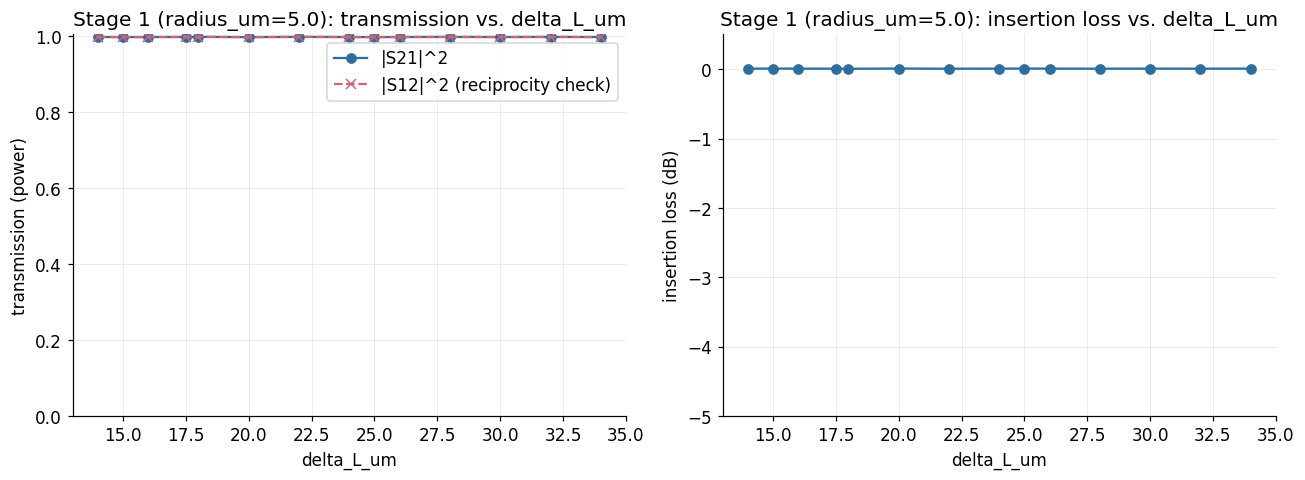

In [5]:
ALL_DELTA_L_UM_STAGE1 = sorted(EXISTING_DELTA_L_UM + NEW_DELTA_L_UM)

def _artifact_dir_and_extra_stage1(delta_L_um):
    if delta_L_um in EXISTING_DELTA_L_UM:
        return Path("../data/sparams/mzi_arm/sweep"), mzi_arm.extra_straight_um_for_delta_L(delta_L_um, params)
    return Path("../data/sparams/mzi_arm/sweep_dense2um"), mzi_arm.extra_straight_um_for_delta_L(delta_L_um, params)

delta_L_achieved, s21_center, s12_center, loss_db_center = [], [], [], []
for dl_target in ALL_DELTA_L_UM_STAGE1:
    art_dir, extra = _artifact_dir_and_extra_stage1(dl_target)
    tag = f"extra_straight{extra}"
    a = sparams.load_artifact(art_dir / f"mzi_arm_{tag}")
    mid = len(a.wavelengths_um) // 2
    s21, s12 = a.s_matrix["21"][mid], a.s_matrix["12"][mid]
    delta_L_achieved.append(mzi_arm.delta_L_um_from_extra(extra, params))
    s21_center.append(np.abs(s21) ** 2)
    s12_center.append(np.abs(s12) ** 2)
    loss_db_center.append(-10 * np.log10(np.abs(s21) ** 2))

delta_L_achieved = np.array(delta_L_achieved)

fig, (ax_t, ax_l) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_t.plot(delta_L_achieved, s21_center, "o-", color=style.COLOR_STEEL, label="|S21|^2")
ax_t.plot(delta_L_achieved, s12_center, "x--", color=style.COLOR_ROSE, label="|S12|^2 (reciprocity check)")
ax_t.set_xlabel("delta_L_um"); ax_t.set_ylabel("transmission (power)")
ax_t.set_title("Stage 1 (radius_um=5.0): transmission vs. delta_L_um")
ax_t.set_ylim(0, 1.005); ax_t.legend()

ax_l.plot(delta_L_achieved, loss_db_center, "o-", color=style.COLOR_STEEL)
ax_l.set_xlabel("delta_L_um"); ax_l.set_ylabel("insertion loss (dB)")
ax_l.set_title("Stage 1 (radius_um=5.0): insertion loss vs. delta_L_um")
ax_l.set_ylim(-5, 0.5)
fig.tight_layout()
plt.show()


## 2. Stage 2 -- radius_um=2.5 dense grid

This stage builds the arm-length library at `radius_um=2.5`, the bend radius of the
Mux4 tree's second-stage arms (`circuits/wdm_mux4_sax.ipynb`), read by
`pic_toolkit.optimization.arm_library.load_arm_length_library(radius_um=2.5)`.

It has two parts. `si/data/sparams/mzi_arm/sweep_r2.5/` holds the two arms
`wdm_mux4_sax.ipynb` composes directly: `delta_L_um=7.5` µm and 7.640 µm (that
notebook's ideal quarter-wave value `DELTA_L_2_UP_UM`). `sweep_r2p5_dense/` holds a
dense grid from 7 to 20 µm for gradient-based search.

In [6]:
params = dict(mzi_arm.DEFAULT_PARAMS)
params["radius_um"] = 2.5  # stage-2 geometry -- DEFAULT_PARAMS's own radius_um=5.0 is stage-1's
params


{'wg_width_um': 0.5,
 'core_index': 2.7,
 'clad_index': 1.44,
 'polarization': 'TE',
 'wl_min_um': 1.3,
 'wl_max_um': 1.4,
 'resolution': 40,
 'dpml_um': 1.0,
 'radius_um': 2.5,
 'bend_type': 'euler',
 'extra_straight_um': 0.864,
 'lead_len_um': 3.0,
 'n_freq': 21,
 'margin_um': 1.5,
 'port_offset_um': 1.0,
 'source_offset_um': 0.5,
 'lead_overrun_um': 1.0}

### 2.1 Target grid

Floor at `radius_um=2.5` (`bend_type="euler"`) is ~6.632um -- all targets
below are safely above it. The dense grid spans the two
`wdm_mux4_sax.ipynb` arms (7.5 and 7.640 µm) up through 20 µm, giving the stage-2
optimizer generous search room.

In [7]:
# The two arms wdm_mux4_sax.ipynb composes (sweep_r2.5/): delta_L_um = 7.5 um and its
# ideal quarter-wave value 7.6401287 um; the second is entered as the extra_straight_um
# that notebook uses, so the artifact name matches what models/mzi_arm.py looks up.
MUX4_EXTRA_STRAIGHT_UM = [mzi_arm.extra_straight_um_for_delta_L(7.5, params), 0.5040643554079294]
print("sweep_r2.5:", [(round(mzi_arm.delta_L_um_from_extra(e, params), 4), round(e, 4)) for e in MUX4_EXTRA_STRAIGHT_UM])

EXISTING_DELTA_L_UM = [7.5]  # plotted from sweep_r2.5/ together with the dense grid
NEW_DELTA_L_UM = [7.0, 8.0, 9.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0]

NEW_EXTRA_STRAIGHT_UM = [mzi_arm.extra_straight_um_for_delta_L(dl, params) for dl in NEW_DELTA_L_UM]
print("sweep_r2p5_dense:", list(zip(NEW_DELTA_L_UM, [round(e, 4) for e in NEW_EXTRA_STRAIGHT_UM])))

sweep_r2.5: [(7.5, 0.434), (7.6401, 0.5041)]
sweep_r2p5_dense: [(7.0, 0.184), (8.0, 0.684), (9.0, 1.184), (10.0, 1.684), (12.0, 2.684), (14.0, 3.684), (16.0, 4.684), (18.0, 5.684), (20.0, 6.684)]


### 2.2 Run the sweeps

Same loose sweep tolerances as the radius=5.0 sweep -- same geometry family,
just a different radius/denser sampling.

> **STOP -- this cell runs FDTD on a first run (2 + 9 points, each a 2-direction
> run; saved points with identical settings are reloaded).**

In [8]:
SWEEP_CHECK_KWARGS = dict(energy_tol=0.15, reciprocity_tol=0.15, passivity_tol=0.05, max_loss_fraction=0.30)

rows_mux4 = sweep.grid_sweep(
    simulate_fn=mzi_arm.simulate_baseline,
    base_params=params,
    param_grid={"extra_straight_um": MUX4_EXTRA_STRAIGHT_UM},
    artifact_dir=Path("../data/sparams/mzi_arm/sweep_r2.5"),
    component_name="mzi_arm",
    check_kwargs=SWEEP_CHECK_KWARGS,
    reuse_existing=True,
)
sweep.save_manifest(rows_mux4, Path("../data/sparams/mzi_arm/sweep_r2.5/manifest.csv"))

sweep_rows_stage2 = sweep.grid_sweep(
    simulate_fn=mzi_arm.simulate_baseline,
    base_params=params,
    param_grid={"extra_straight_um": NEW_EXTRA_STRAIGHT_UM},
    artifact_dir=Path("../data/sparams/mzi_arm/sweep_r2p5_dense"),
    component_name="mzi_arm",
    check_kwargs=SWEEP_CHECK_KWARGS,
    reuse_existing=True,
)
n_passed = sum(row["validation_passed"] for row in sweep_rows_stage2)
n_passed_mux4 = sum(row["validation_passed"] for row in rows_mux4)
print(f"stage 2 (radius=2.5): sweep_r2.5 {n_passed_mux4}/{len(rows_mux4)}, dense grid {n_passed}/{len(sweep_rows_stage2)} points within the (loose) sweep tolerance")
sweep.save_manifest(sweep_rows_stage2, Path("../data/sparams/mzi_arm/sweep_r2p5_dense/manifest.csv"))

[1/2  50%] running mzi_arm (extra_straight_um=0.4339999999999993) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[2/2  100%] running mzi_arm (extra_straight_um=0.5040643554079294) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[1/9  11%] running mzi_arm (extra_straight_um=0.18399999999999928) ...


...

[8/9  88%] running mzi_arm (extra_straight_um=5.683999999999999) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[9/9  100%] running mzi_arm (extra_straight_um=6.683999999999999) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


stage 2 (radius=2.5): sweep_r2.5 2/2, dense grid 9/9 points within the (loose) sweep tolerance


### 2.3 Visualize: transmission and loss across the combined (existing + new) grid

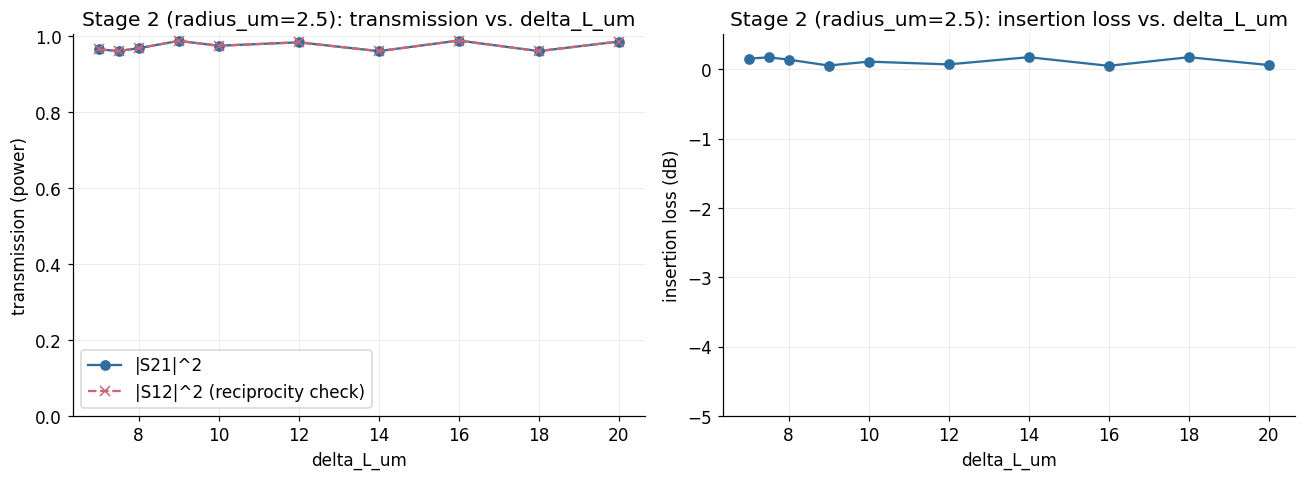

In [9]:
ALL_DELTA_L_UM_STAGE2 = sorted(EXISTING_DELTA_L_UM + NEW_DELTA_L_UM)

def _artifact_dir_and_extra_stage2(delta_L_um):
    if delta_L_um in EXISTING_DELTA_L_UM:
        return Path("../data/sparams/mzi_arm/sweep_r2.5"), mzi_arm.extra_straight_um_for_delta_L(delta_L_um, params)
    return Path("../data/sparams/mzi_arm/sweep_r2p5_dense"), mzi_arm.extra_straight_um_for_delta_L(delta_L_um, params)

delta_L_achieved, s21_center, s12_center, loss_db_center = [], [], [], []
for dl_target in ALL_DELTA_L_UM_STAGE2:
    art_dir, extra = _artifact_dir_and_extra_stage2(dl_target)
    tag = f"extra_straight{extra}"
    a = sparams.load_artifact(art_dir / f"mzi_arm_{tag}")
    mid = len(a.wavelengths_um) // 2
    s21, s12 = a.s_matrix["21"][mid], a.s_matrix["12"][mid]
    delta_L_achieved.append(mzi_arm.delta_L_um_from_extra(extra, params))
    s21_center.append(np.abs(s21) ** 2)
    s12_center.append(np.abs(s12) ** 2)
    loss_db_center.append(-10 * np.log10(np.abs(s21) ** 2))

delta_L_achieved = np.array(delta_L_achieved)

fig, (ax_t, ax_l) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_t.plot(delta_L_achieved, s21_center, "o-", color=style.COLOR_STEEL, label="|S21|^2")
ax_t.plot(delta_L_achieved, s12_center, "x--", color=style.COLOR_ROSE, label="|S12|^2 (reciprocity check)")
ax_t.set_xlabel("delta_L_um"); ax_t.set_ylabel("transmission (power)")
ax_t.set_title("Stage 2 (radius_um=2.5): transmission vs. delta_L_um")
ax_t.set_ylim(0, 1.005); ax_t.legend()

ax_l.plot(delta_L_achieved, loss_db_center, "o-", color=style.COLOR_STEEL)
ax_l.set_xlabel("delta_L_um"); ax_l.set_ylabel("insertion loss (dB)")
ax_l.set_title("Stage 2 (radius_um=2.5): insertion loss vs. delta_L_um")
ax_l.set_ylim(-5, 0.5)
fig.tight_layout()
plt.show()


## 3. Summary

The dense grids are saved to `si/data/sparams/mzi_arm/sweep_dense2um/` (radius 5 µm) and
`si/data/sparams/mzi_arm/sweep_r2p5_dense/` (radius 2.5 µm), next to `sweep/`
(`03_mzi_arm.ipynb`) and `sweep_r2.5/` (the two Mux4 arms, Section 2). Together they give
`pic_toolkit.optimization.arm_library` a dense length-axis S-parameter library at both
bend radii.

All 17 dense-grid points and the 2 Mux4 arms pass the sweep tolerances. At radius 5 µm the
arm is essentially lossless across the whole 14-34 µm range (insertion loss
0.006-0.008 dB at 1.35 µm). At radius 2.5 µm the four bends radiate measurably: 0.17-0.18 dB
for the two Mux4 arms and 0.05-0.17 dB across the dense grid, varying non-monotonically with the inserted
straight length (consistent with interference between the fields scattered at the four
bends, whose spacing changes).